In [ ]:
w0, w1 = 1.0, 1.0
inputs = [1, 2, 3, 4, 5]
targets = [2, 3, 4, 5, 6]

epochs = 1254
N_relax = 100
step = 0.1
lr = 0.1

for epoch in range(epochs):
    for n in range(len(inputs)):
        x0 = inputs[n]
        x2 = targets[n]
        x1 = 0  # reset every example

        for t in range(N_relax):
            e1 = x1 - w0 * x0
            e2 = x2 - w1 * x1
            x1 = x1 + step * (-e1 + w1 * e2)

        e1 = x1 - w0 * x0
        e2 = x2 - w1 * x1
        w0 = w0 + lr * (e1 * x0)
        w1 = w1 + lr * (e2 * x1)

# energy on last example only (after last weight step)
E = 0.5 * ((x1 - w0 * x0) ** 2 + (x2 - w1 * x1) ** 2)
print(w0, w1, x1, E)

0.2731307020437934 4.317057965536442 1.3773046934739972 0.0015310529362762267


Hidden-to-output weight:      tensor([0.9707, 1.0732, 1.1560])
Activity of a hidden neuron:  tensor([4.8468, 5.1960])
Hidden-to-output weight:      tensor(6.0071e-05, grad_fn=<MulBackward0>)


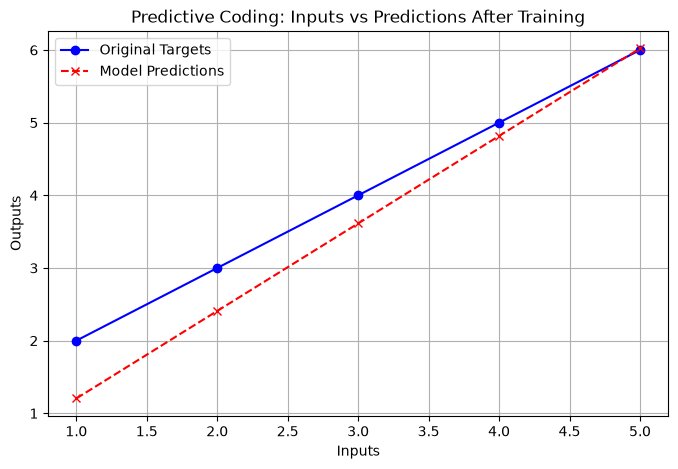

In [4]:
import torch
import matplotlib.pyplot as plt

L = 4
w = torch.ones(L - 1, requires_grad=True)

inputs = [1, 2, 3, 4, 5]
targets = [2, 3, 4, 5, 6]

epochs = 10
N_relax = 100
step = 0.1
lr = 0.1

for epoch in range(epochs):
    for n in range(len(inputs)):
        x0 = inputs[n]
        x_h = torch.zeros(2, requires_grad=True)
        x2 = targets[n]

        for i in range(N_relax):
            # E = 0.5 * ((x2 - w[1] * x1) ** 2 + (x1 - w[0] * x0) ** 2)
            E = 0.5 * (
                (x_h[0] - w[0] * x0) ** 2
                + (x_h[1] - w[1] * x_h[0]) ** 2
                + (x2 - w[2] * x_h[1]) ** 2
            )
            E.backward()
            with torch.no_grad():
                x_h -= step * x_h.grad
            x_h.grad.zero_()

        w.grad.zero_()
        E = 0.5 * (
            (x_h[0] - w[0] * x0) ** 2
            + (x_h[1] - w[1] * x_h[0]) ** 2
            + (x2 - w[2] * x_h[1]) ** 2
        )
        E.backward()
        w.data = w.data - lr * w.grad

E = 0.5 * (
    (x_h[0] - w[0] * x0) ** 2
    + (x_h[1] - w[1] * x_h[0]) ** 2
    + (x2 - w[2] * x_h[1]) ** 2
)

print("Hidden-to-output weight:     ", w.data)
print("Activity of a hidden neuron: ", x_h.data)
print("Hidden-to-output weight:     ", E)


# --- PLOTTING PREDICTIONS ---

# Calculate predictions for each input using the trained weights.
# In a PC network, when the target is unknown, the minimum energy state
# is equivalent to a standard forward pass.
predictions = []
with torch.no_grad():
    for x in inputs:
        # Forward pass: x -> x_h0 -> x_h1 -> prediction
        pred = w[0] * x * w[1] * w[2]
        predictions.append(pred.item())

# Create the plot
plt.figure(figsize=(8, 5))
plt.plot(
    inputs, targets, marker="o", linestyle="-", color="blue", label="Original Targets"
)
plt.plot(
    inputs,
    predictions,
    marker="x",
    linestyle="--",
    color="red",
    label="Model Predictions",
)

plt.xlabel("Inputs")
plt.ylabel("Outputs")
plt.title("Predictive Coding: Inputs vs Predictions After Training")
plt.legend()
plt.grid(True)
plt.show()

predictions: [3.8308932781219482, 3.8308932781219482, 3.8308932781219482, 3.8308932781219482, 3.8308932781219482]


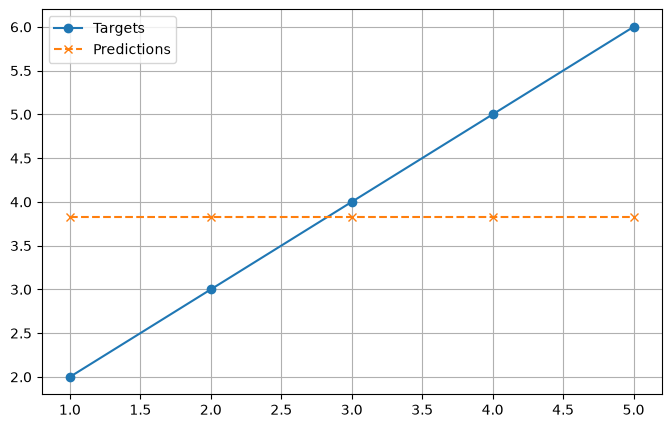

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt


class PCLayer(nn.Module):
    """Activity + energy at this point in the graph. Shape-agnostic."""

    def __init__(self):
        super().__init__()
        self.x = None
        self.energy_value = None

    def reset(self):
        self.x = None
        self.energy_value = None

    def forward(self, mu: torch.Tensor) -> torch.Tensor:
        if not self.training:
            return mu

        if self.x is None or self.x.shape != mu.shape or self.x.device != mu.device:
            self.x = nn.Parameter(mu.detach().clone())

        self.energy_value = 0.5 * ((self.x - mu) ** 2).sum()
        return self.x


def pc_layers(model: nn.Module):
    return [m for m in model.modules() if isinstance(m, PCLayer)]


def activity_params(model: nn.Module):
    return [m.x for m in pc_layers(model) if m.x is not None]


def weight_params(model: nn.Module):
    act_ids = {id(p) for p in activity_params(model)}
    return [p for p in model.parameters() if id(p) not in act_ids]


def pc_energy(model: nn.Module) -> torch.Tensor:
    energies = [m.energy_value for m in pc_layers(model) if m.energy_value is not None]
    if not energies:
        return torch.tensor(0.0)
    return torch.stack([e.reshape(()) for e in energies]).sum()


def reset_pc(model: nn.Module):
    for m in pc_layers(model):
        m.reset()


# Any mix of Linear / Conv / activations. Put PCLayer where you want inferred x.
model = nn.Sequential(
    nn.Linear(1, 2),
    PCLayer(),
    nn.ReLU(),
    nn.Linear(2, 1),
)

# Conv example (same trainer):
# model = nn.Sequential(
#     nn.Conv2d(1, 8, 3, padding=1),
#     PCLayer(),
#     nn.ReLU(),
#     nn.Conv2d(8, 16, 3, padding=1),
#     PCLayer(),
#     nn.ReLU(),
#     nn.AdaptiveAvgPool2d(1),
#     nn.Flatten(),
#     nn.Linear(16, 1),
# )

inputs = [1.0, 2.0, 3.0, 4.0, 5.0]
targets = [2.0, 3.0, 4.0, 5.0, 6.0]
epochs = 10
N_relax = 100
step_x = 0.1
lr = 0.05

model.train()
opt_w = None  # created after first forward (so Linear params exist; x exists after forward)

for epoch in range(epochs):
    for x0, y in zip(inputs, targets):
        x = torch.tensor([x0], dtype=torch.float32)
        target = torch.tensor([y], dtype=torch.float32)

        reset_pc(model)

        # Phase 1 — infer activities
        for _ in range(N_relax):
            out = model(x)
            E = pc_energy(model) + 0.5 * ((out - target) ** 2).sum()
            E.backward()

            with torch.no_grad():
                for a in activity_params(model):
                    if a.grad is not None:
                        a -= step_x * a.grad
                        a.grad.zero_()
            model.zero_grad()

        # Phase 2 — update weights / biases of Linear, Conv, etc.
        if opt_w is None:
            opt_w = torch.optim.SGD(weight_params(model), lr=lr)

        opt_w.zero_grad()
        out = model(x)
        E = pc_energy(model) + 0.5 * ((out - target) ** 2).sum()
        E.backward()
        opt_w.step()


@torch.no_grad()
def predict(x, model):
    was_training = model.training
    model.eval()                       # PCLayer becomes identity
    y = model(torch.as_tensor(x, dtype=torch.float32).reshape(-1))
    model.train(was_training)
    return y


preds = [predict([v], model).item() for v in inputs]
print("predictions:", preds)

plt.figure(figsize=(8, 5))
plt.plot(inputs, targets, "o-", label="Targets")
plt.plot(inputs, preds, "x--", label="Predictions")
plt.legend()
plt.grid(True)
plt.show()

weight shapes: [(2, 1), (2, 2), (1, 2)]
W[0] =
tensor([[0.4327],
        [0.4327]])
W[1] =
tensor([[0.8652, 0.8652],
        [0.8652, 0.8652]])
W[2] =
tensor([[0.7925, 0.7925]])
activities:
  x[0] = tensor([5.])
  x[1] = tensor([2.1820, 2.1820])
  x[2] = tensor([3.7752, 3.7752])
  x[3] = tensor([6.])
energy (last example): 0.0004860087647102773
predictions: [1.1865564584732056, 2.373112916946411, 3.5596694946289062, 4.746225833892822, 5.9327826499938965]


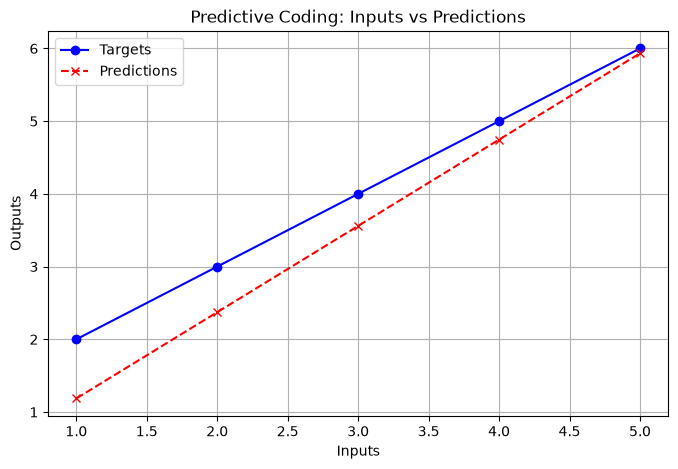

In [ ]:
import torch
import matplotlib.pyplot as plt

# 1 input, 2 hidden, 1 output
layer_sizes = [1, 2, 2, 1]
L = len(layer_sizes)

weights = [
    torch.ones(layer_sizes[i + 1], layer_sizes[i], requires_grad=True)
    for i in range(L - 1)
]


def energy(acts, weights):
    E = 0.0
    for i, W in enumerate(weights):
        err = acts[i + 1] - (W @ acts[i])
        E = E + 0.5 * (err ** 2).sum()
    return E


def init_activities(x0, y):
    acts = [torch.as_tensor(x0, dtype=torch.float32).reshape(layer_sizes[0])]
    for size in layer_sizes[1:-1]:
        acts.append(torch.zeros(size, requires_grad=True))
    acts.append(torch.as_tensor(y, dtype=torch.float32).reshape(layer_sizes[-1]))
    return acts


def predict(x, weights, layer_sizes):
    h = torch.as_tensor(x, dtype=torch.float32).reshape(layer_sizes[0])
    with torch.no_grad():
        for W in weights:
            h = W @ h
    return h


inputs = [1.0, 2.0, 3.0, 4.0, 5.0]
targets = [2.0, 3.0, 4.0, 5.0, 6.0]
epochs = 10
N_relax = 100
step = 0.1
lr = 0.1

for epoch in range(epochs):
    for n in range(len(inputs)):
        acts = init_activities(inputs[n], targets[n])

        for _ in range(N_relax):
            E = energy(acts, weights)
            E.backward()
            with torch.no_grad():
                for a in acts[1:-1]:
                    a -= step * a.grad
                    a.grad.zero_()

        for W in weights:
            if W.grad is not None:
                W.grad.zero_()

        E = energy(acts, weights)
        E.backward()
        with torch.no_grad():
            for W in weights:
                W -= lr * W.grad

# inspect last example — do NOT reuse the name "weights"
E = energy(acts, weights)
print("weight shapes:", [tuple(W.shape) for W in weights])
for i, W in enumerate(weights):
    print(f"W[{i}] =\n{W.data}")
print("activities:")
for i, a in enumerate(acts):
    print(f"  x[{i}] = {a.data}")
print("energy (last example):", float(E))

predictions = []
for x in inputs:
    yhat = predict(x, weights, layer_sizes)
    predictions.append(yhat.item())
print("predictions:", predictions)

plt.figure(figsize=(8, 5))
plt.plot(inputs, targets, marker="o", linestyle="-", color="blue", label="Targets")
plt.plot(inputs, predictions, marker="x", linestyle="--", color="red", label="Predictions")
plt.xlabel("Inputs")
plt.ylabel("Outputs")
plt.title("Predictive Coding: Inputs vs Predictions")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import torch

L = 4
w = torch.ones(L - 1, requires_grad=True)

inputs = [1, 2, 3, 4, 5]
targets = [2, 3, 4, 5, 6]

epochs = 1
lr = 0.1
# N_relax and step are removed because BP does not use iterative inference

for epoch in range(epochs):
    for n in range(len(inputs)):
        x0 = inputs[n]
        x2 = targets[n]

        # 1. FORWARD PASS (deterministic, instant calculation)
        x_h0 = w[0] * x0
        x_h1 = w[1] * x_h0
        pred = w[2] * x_h1

        # 2. LOSS CALCULATION (only at the final output layer)
        loss = 0.5 * (x2 - pred) ** 2

        # 3. BACKWARD PASS
        if w.grad is not None:
            w.grad.zero_()

        loss.backward()  # Computes gradients using the chain rule

        # 4. WEIGHT UPDATE
        with torch.no_grad():
            w -= lr * w.grad

# Final pass on the last example to calculate final state
x_h0 = w[0] * inputs[-1]
x_h1 = w[1] * x_h0
pred = w[2] * x_h1
loss = 0.5 * (targets[-1] - pred) ** 2

print("Weights:                     ", w.data)
print("Activity of hidden neurons:  ", torch.tensor([x_h0.item(), x_h1.item()]))
print("Final Loss:                  ", loss.item())

Weights:                      tensor([-12.9008, -12.9008, -12.9008])
Activity of hidden neurons:   tensor([-64.5042, 832.1573])
Final Loss:                   57690164.0
